# 04 — Integration time, SNR & saturation

This notebook covers the time axis: inverting SNR for an integration time, the SNR-vs-time curve (photon-limited rise vs the speckle plateau), and saturation.

> **Requirements:** this tutorial needs the `config_um` and `config_stp_esc` config repos and an editable install (`pip install -e .`). It uses the **UM 3 m** configuration (the supported path).

In [1]:
import numpy as np
import astropy.units as u
from esc_etc import Simulation, use_lazuli_style, plot_snr_vs_time
use_lazuli_style()

sim = Simulation.from_default(hoststarmag=-0.353, planetdeltamag=20,
                              contrast=1e-8, ppgain=10, separation=0.4)
FT = 100 * u.s

## 1. Invert: how long to reach a target SNR?

`get_int_time_for_snr` is the algebraic inverse of `get_snr`. Feeding the SNR from a 3600 s exposure back in should recover ~3600 s.

In [2]:
T = 3600 * u.s
snr = sim.get_snr(total_time=T, frame_time=FT)['snr']
print('SNR at 3600 s:', round(snr, 4))

out = sim.get_int_time_for_snr(snr, frame_time=FT)
it = out['int_time']
recovered = float(np.atleast_1d(getattr(it, 'value', it))[0])
print('time to reach that SNR:', round(recovered, 1), 's')

assert abs(recovered - 3600.0) / 3600.0 < 1e-3
print('sanity OK: int-time round-trips get_snr (~3600 s)')

SNR at 3600 s: 9.5925
time to reach that SNR: 3600.0 s
sanity OK: int-time round-trips get_snr (~3600 s)


## 2. SNR vs integration time

Early on SNR rises with the square root of time (photon-limited); once the speckle floor dominates it plateaus (set by `ppgain`).

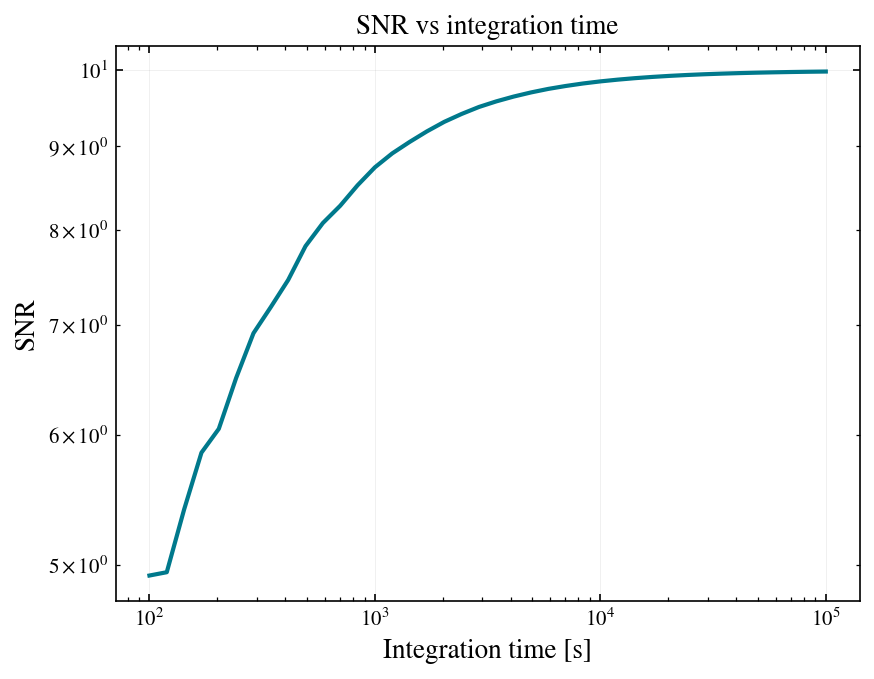

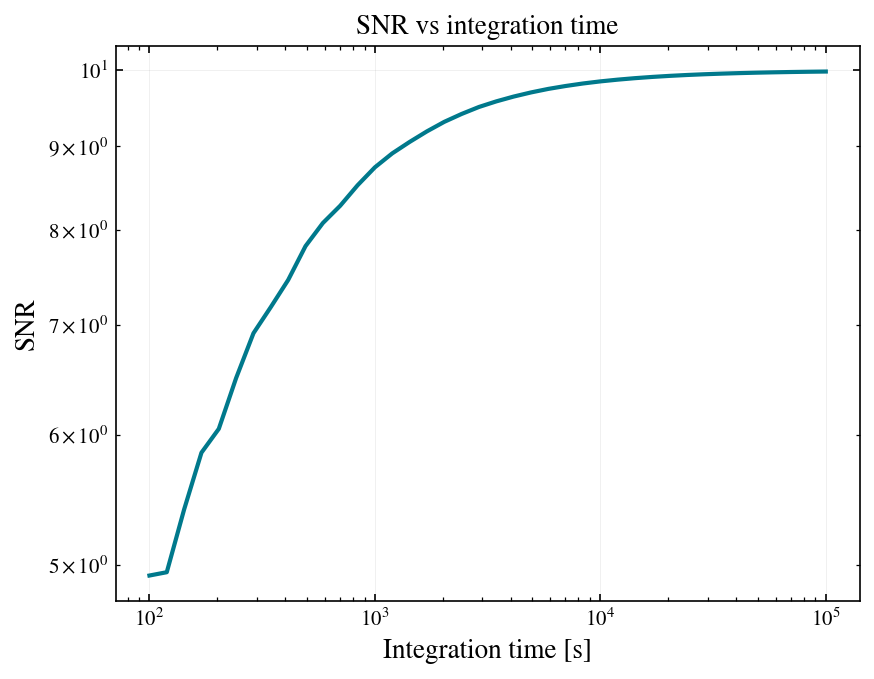

In [3]:
fig, ax = plot_snr_vs_time(sim, frame_time=FT)
ax.set_title('SNR vs integration time')
fig

## 3. Saturation

`saturation_time()` is when the brightest contributors fill the well; `is_saturated(frame_time)` flags a per-frame time against it.

In [4]:
st = sim.saturation_time()
print('saturation time     :', st)
print('is_saturated(10 s)  :', bool(sim.is_saturated(10 * u.s)))
print('is_saturated(2x sat):', bool(sim.is_saturated(2 * st)))

saturation time     : 151885.57097586337 s
is_saturated(10 s)  : False


is_saturated(2x sat): True


## What you learned

- `get_int_time_for_snr` inverts `get_snr` for a target SNR.
- `plot_snr_vs_time` shows the photon-limited rise and the speckle plateau.
- `saturation_time()` / `is_saturated()` flag detector saturation.

That completes the tutorial suite — see the `esc_etc.plotting` helpers and the design docs under `docs/superpowers/` for more.